# TF-IDF

Based on Term Frequency/Inverted Index last time

The text files are placed in hdfs folder '/input', i.e. we have several files in the folder.

The wholeTextFiles will read the files, and output a tuple (filename, fulltext)

data (i.e., wholeTextFiles) -> (filename, fulltext)

Here we calculate the tf "Term Frequency":
**tf = 1+log10(tf)**

In [8]:
import re
def removeSomeTexts(text):
    return re.sub(r"[^a-z-'\s]",'', text)

In [9]:
from pyspark import SparkConf, SparkContext
import os, re
from pyspark.sql.session import SparkSession
import math

spark = SparkSession.builder.master('local').appName('MyTf-Idf').getOrCreate()
sc = spark.sparkContext
#sc = SparkContext.getOrCreate(SparkConf())

sc._conf.set('spark.executor.memory', '8g')
sc._conf.set('spark.driver.memory', '8g')
sc._conf.set('spark.driver.maxResultsSize', '0')

# you need to start hadoop first!!!
# start-dfs.sh
# start-yarn.sh
# make sure you have put data files from your local to /hdfs/input
# hdfs dfs -mkdir /hdfs
# hdfs dfs -mkdir /input
# hdfs dfs -put  yourlocalpath/*.txt  /hdfs/input
# double check the file are uploaded or not
# hdfs dfs -ls /hdfs/input
#data (i.e., wholeTextFiles) -> (filename, fulltext)
data = sc.wholeTextFiles('hdfs://localhost:9000/hdfs/input')  #small, it is ok
#data = sc.wholeTextFiles('hdfs://localhost:9000/hdfs/book1g') #large, failed
#data = sc.wholeTextFiles('hdfs://localhost:9000/hdfs/book500m')

numFiles = data.count()  

In [10]:
wordcount = data.flatMap(lambda x: [((os.path.basename(x[0]), removeSomeTexts(i.lower())), 1) for i in re.split('\W+', x[1])]) \
        .reduceByKey(lambda a, b: a + b)\
        .map(lambda x: (x[0][1],(x[0][0],x[1])))\
        .filter(lambda x: x[0] != '')
wordcount.take(10)   

[('title', ('1080-0.txt', 2)),
 ('a', ('1080-0.txt', 91)),
 ('modest', ('1080-0.txt', 1)),
 ('proposal', ('1080-0.txt', 5)),
 ('for', ('1080-0.txt', 48)),
 ('preventing', ('1080-0.txt', 2)),
 ('the', ('1080-0.txt', 171)),
 ('children', ('1080-0.txt', 20)),
 ('of', ('1080-0.txt', 138)),
 ('poor', ('1080-0.txt', 7))]

In [11]:
# tf = 1+log10(tf)
tf = wordcount.map(lambda x: (x[0],(x[1][0], 1+math.log10((x[1][1]) ))))
tf.take(10)

[('title', ('1080-0.txt', 1.3010299956639813)),
 ('a', ('1080-0.txt', 2.959041392321094)),
 ('modest', ('1080-0.txt', 1.0)),
 ('proposal', ('1080-0.txt', 1.6989700043360187)),
 ('for', ('1080-0.txt', 2.681241237375587)),
 ('preventing', ('1080-0.txt', 1.3010299956639813)),
 ('the', ('1080-0.txt', 3.2329961103921536)),
 ('children', ('1080-0.txt', 2.3010299956639813)),
 ('of', ('1080-0.txt', 3.1398790864012365)),
 ('poor', ('1080-0.txt', 1.845098040014257))]

## Computing Inverse Document Frequency (IDF)

The IDF score tells us how important is a particular word in the whole corpus. For instance, if a word is appearing in each document then the IDF score will be zero for that.

We know that the total number of documents for our case is 3. So, our next step will be to compute how many documents contain a particular token w. Further, we can use this information to calculate the IDF scores for all the tokens in the corpus.

We will be chaining the previous map/reduce computation to calculate IDF in this section. After the reduced step in the previous section, we obtained key/value pairs for respective tokens along with its term frequency.

In the first step, we will map the previous key/value pair to a new key/value pair. Here, the key will the token and its value will be the document id TF for that token along with a counter of 1. This one here indicates the presence of a word in document id associated with that.

 ((token, (filename, TF)) -> (token, 1)

Then, we will reduce by key to obtain the count of documents containing a particular token w (wordcount).

(token, 1) -> (token, 1+1+1+...)

In the last step, since we have the number of documents containing each token w, we will just map this final output with the logarithmic transformation to compute the IDF score.

(token, doc-freq-containing-token) -> (token, IDF)

In [12]:
idf = wordcount.map(lambda x: (x[0], 1))\
        .reduceByKey(lambda x, y: x + y)\
        .map(lambda x: (x[0], math.log10(numFiles / (x[1]))))
idf.take(10)

[('title', 0.028028723600243534),
 ('a', 0.0),
 ('modest', 0.16272729749769976),
 ('proposal', 0.16272729749769976),
 ('for', 0.0),
 ('preventing', 0.6020599913279624),
 ('the', 0.0),
 ('children', 0.0),
 ('of', 0.0),
 ('poor', 0.0)]

In [ ]:
#Do it ste by step and you can check each step values

# ((token, filename), TF) -> (token, 1)
idf2 = wordcount.map(lambda x: (x[0], 1))
#idf2.take(10)

# (token, 1) -> (token, 1+1+1+...)
idf3 = idf2.reduceByKey(lambda x, y: x + y)
#idf3.take(10)

# (token, doc-freq-containing-token) -> (token, IDF)
idf = idf3.map(lambda x: (x[0], math.log10(numFiles / (x[1]))))
idf.take(10)

## Computing TF-IDF

Now we have two RDDs one having the document id along with its document term frequency for each token. Another RDD having IDF scores for each token.

First, we will perform an inner join to assign each token with a document id, TF, and IDF score.

Second, we will map this function to multiply TF and IDF values of each token associated with respective document id.

Third, we sort the key

New Key/Value pair -> (filename, (token, TF-IDF))

In [13]:
# put it together
tfidf = tf.join(idf).map(lambda x: (x[1][0][0], (x[0], x[1][0][1] * x[1][1]))).sortByKey()\
        .map(lambda x:(x[1][0], (x[0], x[1][1]))).filter(lambda x: x[0]!='')\
        .sortByKey()
tfidf.take(50)

[('a', ('1080-0.txt', 0.0)),
 ('a', ('11-0.txt', 0.0)),
 ('a', ('120-0.txt', 0.0)),
 ('a', ('1342-0.txt', 0.0)),
 ('a', ('1400-8.txt', 0.0)),
 ('a', ('203-0.txt', 0.0)),
 ('a', ('2600-0.txt', 0.0)),
 ('a', ('36-0.txt', 0.0)),
 ('a', ('74-0.txt', 0.0)),
 ('a', ('76-0.txt', 0.0)),
 ('a', ('98-0.txt', 0.0)),
 ('a', ('dolls_house.txt', 0.0)),
 ('a', ('frankenstein.txt', 0.0)),
 ('a', ('monte_cristo.txt', 0.0)),
 ('a', ('sherlock.txt', 0.0)),
 ('a', ('ulysses.txt', 0.0)),
 ('aah', ('2600-0.txt', 1.2041199826559248)),
 ('aaron', ('monte_cristo.txt', 0.9030899869919435)),
 ('aaron', ('ulysses.txt', 1.1749471618603131)),
 ('ab', ('2600-0.txt', 0.9030899869919435)),
 ('ab', ('76-0.txt', 1.3339734147103033)),
 ('aback', ('120-0.txt', 0.7461677697975099)),
 ('aback', ('1400-8.txt', 0.505149978319906)),
 ('aback', ('2600-0.txt', 0.7461677697975099)),
 ('aback', ('98-0.txt', 0.505149978319906)),
 ('aback', ('ulysses.txt', 0.505149978319906)),
 ('abacus', ('2600-0.txt', 1.2041199826559248)),
 ('abaf

In [14]:
#save tfidf index as parquet format in hdfs format
lines = tfidf.map(lambda x: (x[0], x[1][0], x[1][1])).toDF()

# If you have already this directory, delete it first
# hdfs dfs -rm -r /hdfs/output/tfidf_index
#lines.write.save('hdfs://localhost:9000/hdfs/output/tfidf_index')

# you can also save your result in your local file system
# If you already have this directory, delete it first
lines.write.save("data/tfidf_index3")

## Do it step by step

In [ ]:
tfidf1 = tf.join(idf)
tfidf1.take(10)

In [ ]:
tfidf = tfidf1.map(lambda x: (x[1][0][0], (x[0], x[1][0][1] * x[1][1]))).sortByKey()
tfidf.take(10)

In [ ]:
index = tfidf.map(lambda x:(x[1][0], (x[0], x[1][1]))).filter(lambda x: x[0]!='')
index.take(10)

In [ ]:
index = index.sortByKey()
index.take(100)

In [ ]:
#save tfidf index as parquet format in hdfs format
lines = index.map(lambda x: (x[0], x[1][0], x[1][1])).toDF()

# If you have already this directory, delete it first
# hdfs dfs -rm -r /hdfs/output/tfidf_index
lines.write.save('hdfs://localhost:9000/hdfs/output/tfidf_index')

You can find your result in /hdfs/output/tfidf_index:
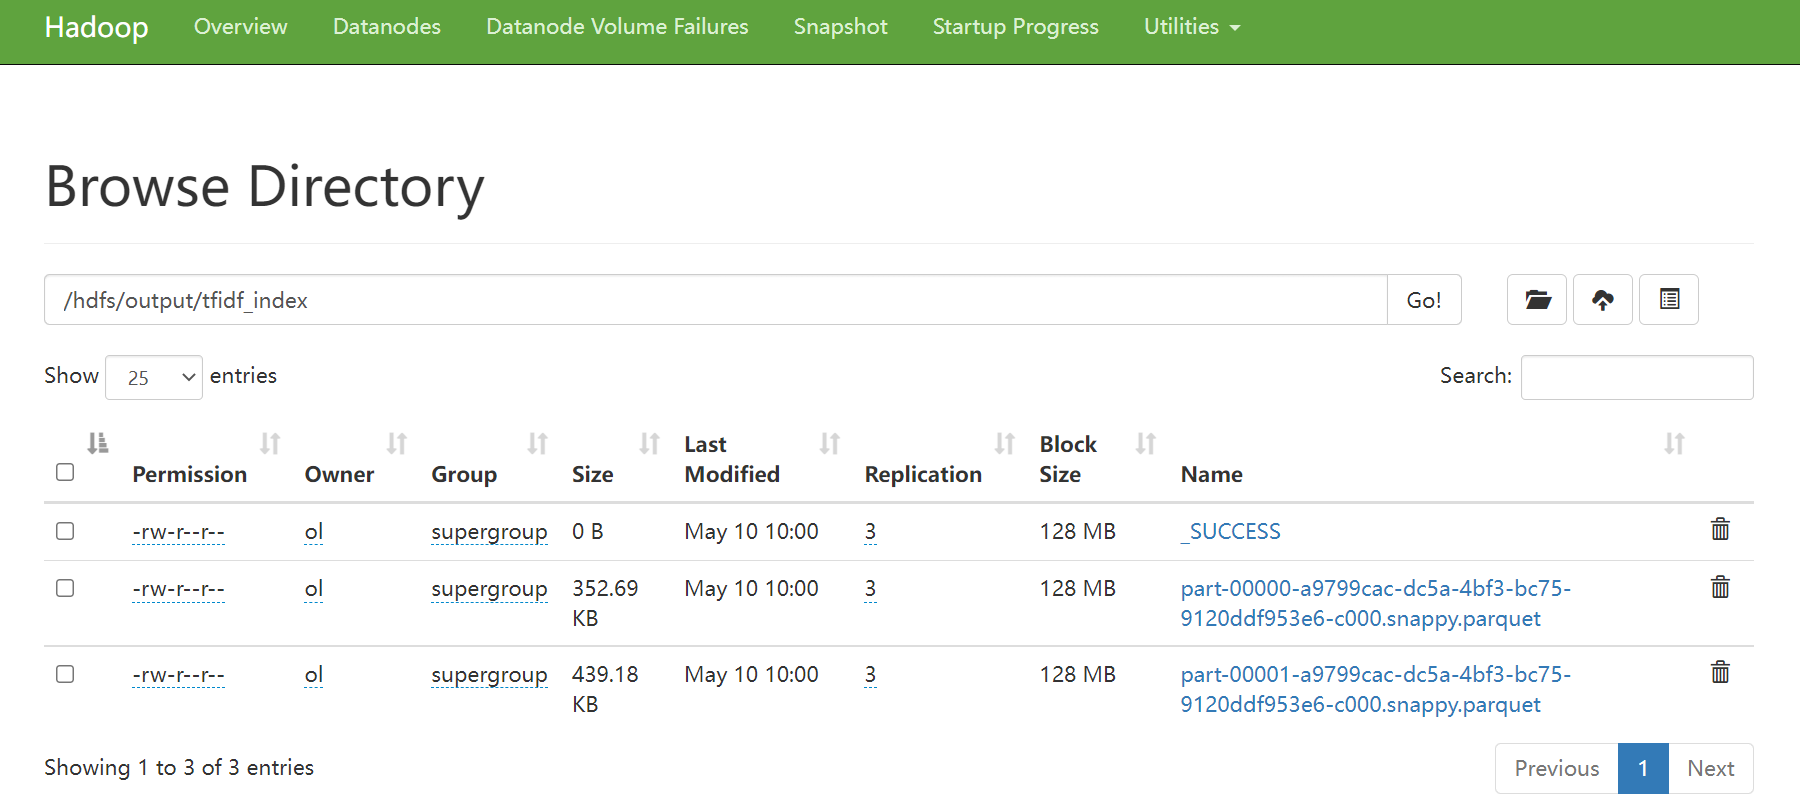

In [ ]:
# you can also save your result in your local file system
# If you already have this directory, delete it first
lines.write.save("data/tfidf_index")